# CA1: AI, Data Science and Software Employment in the USA

**Name:** YOUR NAME  
**Student number:** 2023461 
**GitHub repository:** PASTE LINK  
**Video link:** PASTE LINK  

This notebook uses the May 2023 Occupational Employment and Wage Statistics data from the U.S. Bureau of Labor Statistics. I look at seven occupations connected to AI, data science and software development, and for each chart I explain the objective, why I picked that chart type, and what I learned from it.

## Loading and preparing the data

The dataset repeats each occupation at many levels (national, state, metro area and industry), so I filter to one level before each chart to avoid counting the same jobs twice. Some wage and employment values are stored as symbols such as * and #, so I convert those columns to numbers first.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("data/all_data_M_2023.xlsx")
df.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


In [2]:
print(df.shape)
print(df.columns.tolist())
print(df["AREA_TYPE"].value_counts())
print(df["O_GROUP"].value_counts())

(413327, 32)
['AREA', 'AREA_TITLE', 'AREA_TYPE', 'PRIM_STATE', 'NAICS', 'NAICS_TITLE', 'I_GROUP', 'OWN_CODE', 'OCC_CODE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP', 'EMP_PRSE', 'JOBS_1000', 'LOC_QUOTIENT', 'PCT_TOTAL', 'PCT_RPT', 'H_MEAN', 'A_MEAN', 'MEAN_PRSE', 'H_PCT10', 'H_PCT25', 'H_MEDIAN', 'H_PCT75', 'H_PCT90', 'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90', 'ANNUAL', 'HOURLY']
AREA_TYPE
1    177501
4    149591
6     48559
2     36643
3      1033
Name: count, dtype: int64
O_GROUP
detailed    306185
broad        62131
minor        23374
major        20601
total         1036
Name: count, dtype: int64


In [3]:
num_cols = ["TOT_EMP", "A_MEAN", "A_MEDIAN", "A_PCT10", "A_PCT25", "A_PCT75", "A_PCT90"]
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [4]:
jobs = {
    "15-2051": "Data Scientists",
    "15-1252": "Software Developers",
    "15-1221": "Computer & Info Research Scientists",
    "15-1243": "Database Architects",
    "15-2041": "Statisticians",
    "15-1253": "Software QA Analysts & Testers",
    "15-1211": "Computer Systems Analysts",
}
tech = df[df["OCC_CODE"].isin(jobs.keys())].copy()
tech["JOB"] = tech["OCC_CODE"].map(jobs)

In [5]:
national = tech[(tech["AREA_TYPE"] == 1) & (tech["I_GROUP"] == "cross-industry")]
states = tech[tech["AREA_TYPE"] == 2]
industry = tech[(tech["AREA_TYPE"] == 1) & (tech["I_GROUP"] == "sector")]

national[["JOB", "TOT_EMP", "A_MEAN", "A_MEDIAN"]]

,JOB,TOT_EMP,A_MEAN,A_MEDIAN
135,Computer Systems Analysts,498810.0,110800.0,103800.0
138,Computer & Info Research Scientists,35210.0,157160.0,145080.0
145,Database Architects,59920.0,137030.0,134700.0
149,Software Developers,1656880.0,138110.0,132270.0
150,Software QA Analysts & Testers,203040.0,108460.0,101800.0
163,Statisticians,29950.0,109190.0,104110.0
165,Data Scientists,192710.0,119040.0,108020.0


## 1. Bar Chart: Employment by Occupation

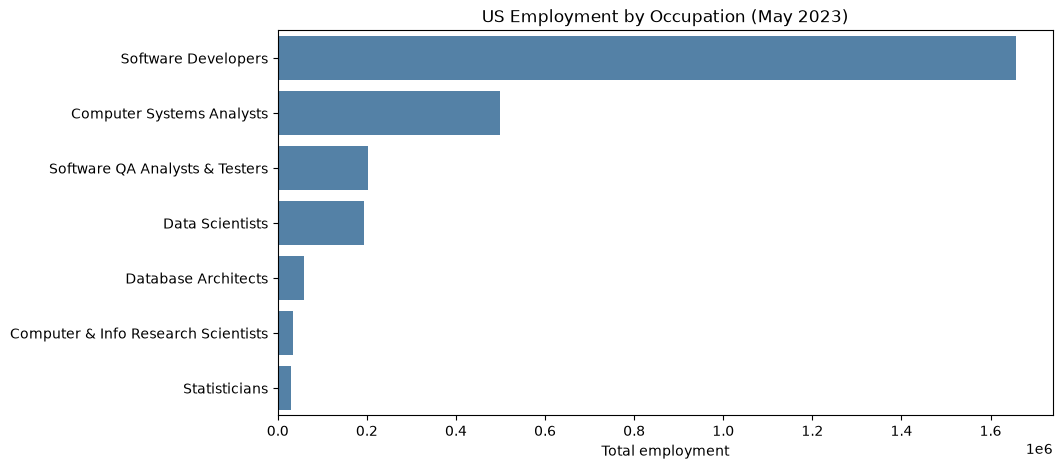

In [6]:
d = national.sort_values("TOT_EMP", ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(x="TOT_EMP", y="JOB", data=d, color="steelblue")
plt.title("US Employment by Occupation (May 2023)")
plt.xlabel("Total employment")
plt.ylabel("")
plt.show()

- **Objective:** To compare how many people work in each of the seven occupations across the whole USA.
- **Why this plot:** Each occupation is a category with one number attached, and a bar chart is the simplest way to compare those. I made it horizontal because the job titles are long and would overlap on a vertical axis. I also sorted the bars so the ranking is obvious.
- **Learning:** Software Developers are far ahead of everything else with about 1.66 million jobs, which is more than 8 times the number of Data Scientists (192,710). The roles closest to AI research are very small in comparison: Computer and Information Research Scientists have only 35,210 jobs and Statisticians 29,950. So most employment in this area is in building software, not in research.

## 2. Pie Chart: Share of Employment

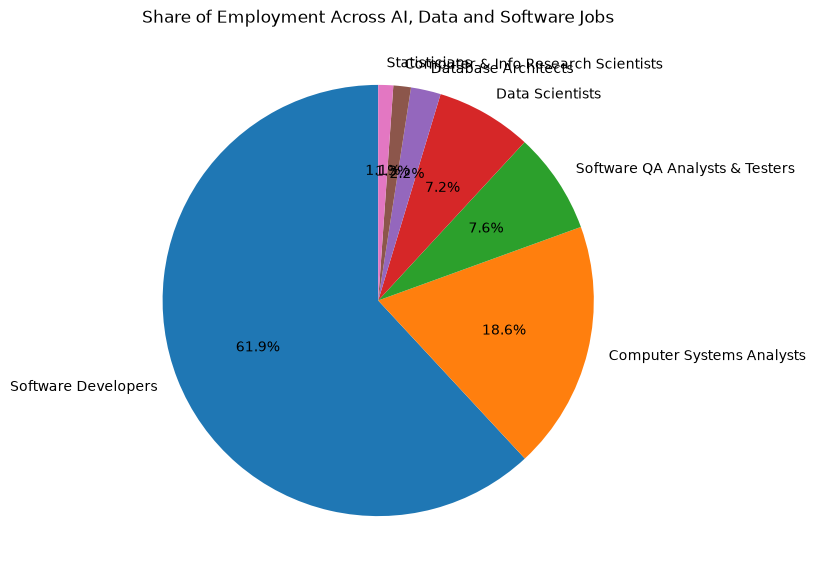

In [7]:
plt.figure(figsize=(7, 7))
plt.pie(d["TOT_EMP"], labels=d["JOB"], autopct="%1.1f%%", startangle=90)
plt.title("Share of Employment Across AI, Data and Software Jobs")
plt.show()

- **Objective:** To see what share of the total each occupation makes up, instead of the raw counts.
- **Why this plot:** A pie chart works for part-of-a-whole data when there are only a few categories. Here there are seven, and one clearly dominates, which a pie shows well.
- **Learning:** Software Developers make up 61.9% of the seven occupations combined. Computer Systems Analysts are second at 18.6%, then QA Analysts and Testers at 7.6% and Data Scientists at 7.2%. Database Architects, Research Scientists and Statisticians together are under 5%. A weakness of the pie chart is that these small slices are hard to tell apart, which is why I used the bar chart as well.

## 3. Horizontal Bar Chart: Top 10 States for Data Scientists

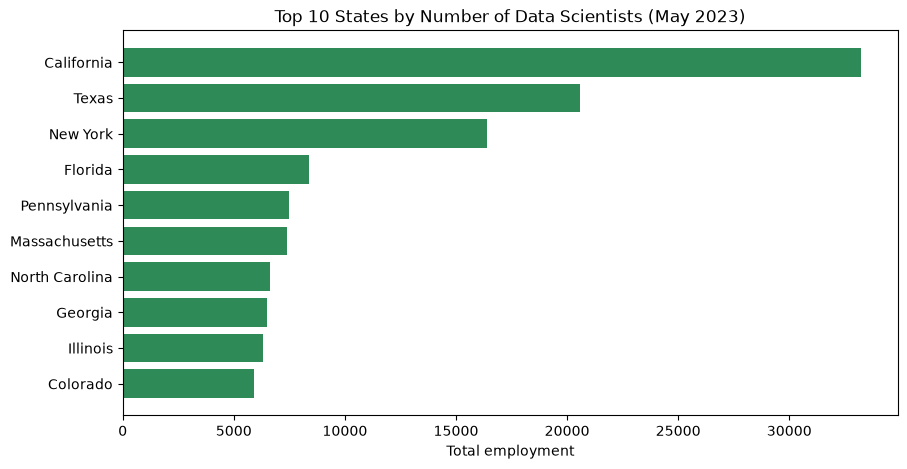

In [8]:
ds = states[states["OCC_CODE"] == "15-2051"].sort_values("TOT_EMP", ascending=False).head(10)
plt.figure(figsize=(10, 5))
plt.barh(ds["AREA_TITLE"], ds["TOT_EMP"], color="seagreen")
plt.gca().invert_yaxis()
plt.title("Top 10 States by Number of Data Scientists (May 2023)")
plt.xlabel("Total employment")
plt.show()

- **Objective:** To find out where in the USA data scientists are concentrated.
- **Why this plot:** This is a ranking, and a horizontal bar chart reads naturally from top to bottom with the state names easy to read. I limited it to the top 10 because 50 bars would be too cluttered.
- **Learning:** California has the most data scientists with 33,220, followed by Texas (20,560) and New York (16,390). These three states alone hold about 36% of all data scientists in the country. Data science jobs are clearly clustered in states with large tech and finance sectors and are not spread evenly.

## 4. Boxplot: Wage Distribution Across States

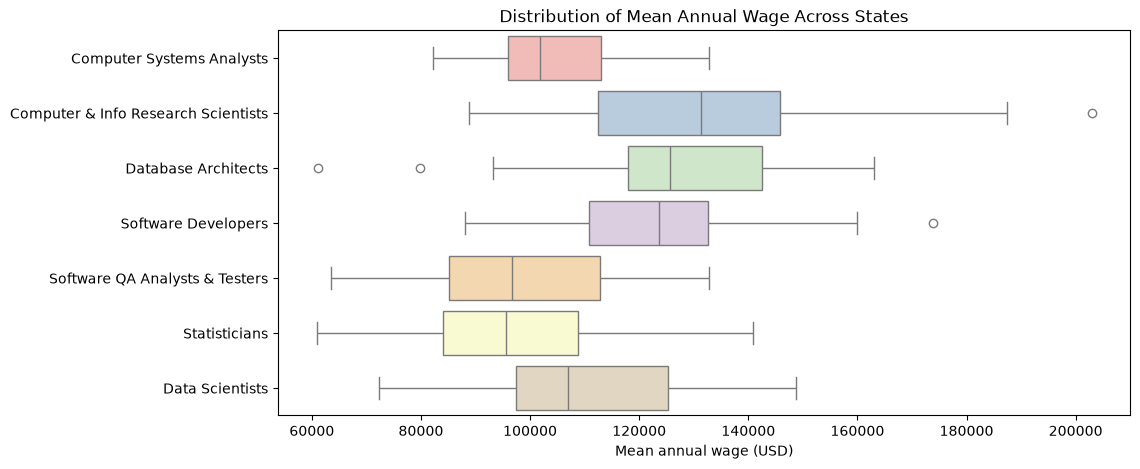

In [9]:
plt.figure(figsize=(11, 5))
sns.boxplot(x="A_MEAN", y="JOB", hue="JOB", data=states, palette="Pastel1", legend=False)
plt.title("Distribution of Mean Annual Wage Across States")
plt.xlabel("Mean annual wage (USD)")
plt.ylabel("")
plt.show()

- **Objective:** To compare how the average wage for each occupation varies from state to state.
- **Why this plot:** I wanted to see more than a single average. A boxplot shows the median, the spread and any outliers together, so I can compare both the level and the consistency of pay for each job.
- **Learning:** Computer and Information Research Scientists have the highest median state wage at around $131,000 and also the widest spread, from about $89,000 to $203,000 depending on the state. Software QA Analysts and Statisticians are the lowest, with medians near $96,000. This suggests the roles closest to AI research pay the most, but what you earn depends a lot on where you work.